# Entrenamiento de M2 segmentación de vehículosy M3 keypoints de llantas
Datasets en Roboflow, entrenamiento en Google Colab, pesos y métricas en Google Drive

|

## 1. Instalación y Drive

In [1]:
!pip -q install -U ultralytics roboflow
import os, json, shutil, glob, time
from google.colab import drive, userdata
drive.mount('/content/drive')
SALIDA = '/content/drive/MyDrive/peaje'
os.makedirs(SALIDA, exist_ok=True)
import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'SIN GPU')

Mounted at /content/drive
GPU: Tesla T4


## 2. Configuración

In [2]:
WORKSPACE = 'gisselle-andrea-severich-aramayo-s-workspace'
M2_PROYECTO, M2_VERSION = 'peaje-vehiculos', 2
M3_PROYECTO, M3_VERSION = 'peaje-llantas', 1

EPOCAS_M2, EPOCAS_M3 = 80, 100
IMGSZ_M2, IMGSZ_M3 = 640, 960

from roboflow import Roboflow
rf = Roboflow(api_key=userdata.get('ROBOFLOW_API_KEY'))
def bajar(proyecto, version, formatos):
    for f in formatos:
        try:
            ds = rf.workspace(WORKSPACE).project(proyecto).version(version).download(f)
            print('Descargado en formato', f, '->', ds.location); return ds
        except Exception as e:
            print('Formato', f, 'no disponible:', str(e)[:120])
    raise RuntimeError('No se pudo descargar ' + proyecto)

def contar(ds):
    n = {}
    for sp in ('train', 'valid', 'val', 'test'):
        d = os.path.join(ds.location, sp, 'images')
        if os.path.isdir(d): n[sp] = len(os.listdir(d))
    return n

## 3. M2 · Segmentación de instancias (categoría del vehículo → tarifa)

In [3]:
from ultralytics import YOLO
ds2 = bajar(M2_PROYECTO, M2_VERSION, ['yolov11', 'yolov8'])
print('Imágenes por partición:', contar(ds2))
m2 = YOLO('yolo11s-seg.pt')
m2.train(data=ds2.location + '/data.yaml', epochs=EPOCAS_M2, imgsz=IMGSZ_M2, batch=16, device=0,
         project='/content/runs/m2', name='vehiculos', exist_ok=True, patience=25)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Peaje---Vehículos-2 in yolov11:: 100%|██████████| 207/207 [00:00<00:00, 4195.76it/s]


Descargado en formato yolov11 -> /content/Peaje---Vehículos-2
Imágenes por partición: {'train': 41, 'valid': 27, 'test': 33}
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/Peaje---Vehículos-2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=

ultralytics.utils.metrics.SegmentMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c1ad210c910>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(M)', 'F1-Confidence(M)', 'Precision-Confidence(M)', 'Recall-Confidence(M)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,  

In [4]:
# Métricas de M2
best = '/content/runs/m2/vehiculos/weights/best.pt'
v = YOLO(best).val(data=ds2.location + '/data.yaml', imgsz=IMGSZ_M2, verbose=False)
met2 = {'modelo': 'YOLO11s-seg', 'imagenes': contar(ds2), 'clases': list(v.names.values()), 'epocas': EPOCAS_M2,
        'mAP50_caja': round(float(v.box.map50), 4), 'mAP50-95_caja': round(float(v.box.map), 4),
        'mAP50_mascara': round(float(v.seg.map50), 4), 'mAP50-95_mascara': round(float(v.seg.map), 4)}
print(json.dumps(met2, indent=2, ensure_ascii=False))
shutil.copy(best, SALIDA + '/m2_vehiculos.pt')
json.dump(met2, open(SALIDA + '/metricas_m2.json', 'w'), indent=2, ensure_ascii=False)
for f in glob.glob('/content/runs/m2/vehiculos/*.png'): shutil.copy(f, SALIDA + '/m2_' + os.path.basename(f))   # curvas y matriz de confusión
print('Guardado en', SALIDA)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-seg summary (fused): 113 layers, 10,068,751 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1437.0±487.8 MB/s, size: 30.7 KB)
val: Scanning /content/Peaje---Vehículos-2/valid/labels.cache... 27 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 27/27 7.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 2/2 1.1s/it 2.2s
                   all         27         57      0.355      0.247      0.235      0.187      0.338      0.276      0.235      0.182
Speed: 3.1ms preprocess, 14.8ms inference, 0.0ms loss, 6.6ms postprocess per image
Results saved to /content/runs/segment/val
{
  "modelo": "YOLO11s-seg",
  "imagenes": {
    "train": 41,
    "valid": 27,
    "test": 33
  },
  "clases": [
    "auto",
    "bus",
    "camion",
    "minibus",
    "moto"

## 4. M3 · Keypoints de llantas


In [5]:
import os
import random
import shutil

def crear_particion_validacion_local(ds_location, porcentaje_val=0.15):
    """
    Toma imágenes de la partición 'train' y las mueve a 'valid' para simular
    el conjunto de validación que le falta al dataset.
    """
    train_img_dir = os.path.join(ds_location, 'train', 'images')
    train_lbl_dir = os.path.join(ds_location, 'train', 'labels')
    valid_img_dir = os.path.join(ds_location, 'valid', 'images')
    valid_lbl_dir = os.path.join(ds_location, 'valid', 'labels')


    os.makedirs(valid_img_dir, exist_ok=True)
    os.makedirs(valid_lbl_dir, exist_ok=True)

    imagenes = [f for f in os.listdir(train_img_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    num_val = int(len(imagenes) * porcentaje_val)


    if len(os.listdir(valid_img_dir)) > 0:
        print(f"La carpeta de validación ya contiene {len(os.listdir(valid_img_dir))} imágenes. No se requiere ajuste.")
        return

    if num_val == 0:
        print("El dataset es demasiado pequeño para dividirlo localmente.")
        return

    print(f"Moviendo {num_val} imágenes de 'train' a 'valid' para validación local...")
    val_seleccionadas = random.sample(imagenes, num_val)

    for img_name in val_seleccionadas:

        shutil.move(os.path.join(train_img_dir, img_name), os.path.join(valid_img_dir, img_name))

        lbl_name = os.path.splitext(img_name)[0] + '.txt'
        src_lbl = os.path.join(train_lbl_dir, lbl_name)
        if os.path.exists(src_lbl):
            shutil.move(src_lbl, os.path.join(valid_lbl_dir, lbl_name))

    print("División local completada exitosamente.")

In [6]:
ds3 = bajar(M3_PROYECTO, M3_VERSION, ['yolov11', 'yolov8'])

crear_particion_validacion_local(ds3.location, porcentaje_val=0.15)

print('Imágenes por partición corregidas:', contar(ds3))


m3 = YOLO('yolo11s-pose.pt')
m3.train(data=ds3.location + '/data.yaml', epochs=EPOCAS_M3, imgsz=IMGSZ_M3, batch=8, device=0,
         project='/content/runs/m3', name='llantas', exist_ok=True, patience=30)

loading Roboflow workspace...
loading Roboflow project...
Formato yolov11 no disponible: {"error":"yolov11 is an invalid format for project type keypoint-detection. Please use one of: coco, yolov8, yolo26, yol
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to peaje-llantas-1 in yolov8:: 100%|██████████| 195/195 [00:00<00:00, 7477.09it/s]


Descargado en formato yolov8 -> /content/peaje-llantas-1
Moviendo 14 imágenes de 'train' a 'valid' para validación local...
División local completada exitosamente.
Imágenes por partición corregidas: {'train': 82, 'valid': 14}
Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/peaje-llantas-1/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou

ultralytics.utils.metrics.PoseMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c1b9bcd7d20>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(P)', 'F1-Confidence(P)', 'Precision-Confidence(P)', 'Recall-Confidence(P)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    

In [7]:
ds3 = bajar(M3_PROYECTO, M3_VERSION, ['yolov11', 'yolov8'])
print('Imágenes por partición:', contar(ds3)); print(open(ds3.location + '/data.yaml').read())
m3 = YOLO('yolo11s-pose.pt')
m3.train(data=ds3.location + '/data.yaml', epochs=EPOCAS_M3, imgsz=IMGSZ_M3, batch=8, device=0,
         project='/content/runs/m3', name='llantas', exist_ok=True, patience=30, val=False)

loading Roboflow workspace...
loading Roboflow project...
Formato yolov11 no disponible: {"error":"yolov11 is an invalid format for project type keypoint-detection. Please use one of: coco, yolov8, yolo26, yol
loading Roboflow workspace...
loading Roboflow project...
Descargado en formato yolov8 -> /content/peaje-llantas-1
Imágenes por partición: {'train': 82, 'valid': 14}
flip_idx:
- 0
- 1
- 2
- 3
- 4
kpt_shape:
- 5
- 3
names:
- llanta
nc: 1
roboflow:
  license: CC BY 4.0
  project: peaje-llantas
  url: https://universe.roboflow.com/gisselle-andrea-severich-aramayo-s-workspace/peaje-llantas/dataset/1
  version: 1
  workspace: gisselle-andrea-severich-aramayo-s-workspace
test: ../test/images
train: ../train/images
val: ../valid/images

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, cl

ultralytics.utils.metrics.PoseMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7c19605694e0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(P)', 'F1-Confidence(P)', 'Precision-Confidence(P)', 'Recall-Confidence(P)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    

In [8]:
best = '/content/runs/m3/llantas/weights/best.pt'
v = YOLO(best).val(data=ds3.location + '/data.yaml', imgsz=IMGSZ_M3, verbose=False)
met3 = {'modelo': 'YOLO11s-pose', 'imagenes': contar(ds3), 'epocas': EPOCAS_M3,
        'mAP50_caja': round(float(v.box.map50), 4), 'mAP50-95_caja': round(float(v.box.map), 4),
        'mAP50_keypoints': round(float(v.pose.map50), 4), 'mAP50-95_keypoints': round(float(v.pose.map), 4)}
print(json.dumps(met3, indent=2, ensure_ascii=False))
shutil.copy(best, SALIDA + '/m3_llantas.pt')
json.dump(met3, open(SALIDA + '/metricas_m3.json', 'w'), indent=2, ensure_ascii=False)
for f in glob.glob('/content/runs/m3/llantas/*.png'): shutil.copy(f, SALIDA + '/m3_' + os.path.basename(f))
print('Guardado en', SALIDA)

Ultralytics 8.4.218 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s-pose summary (fused): 109 layers, 9,700,560 parameters, 0 gradients, 22.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1464.3±316.3 MB/s, size: 50.2 KB)
val: Scanning /content/peaje-llantas-1/valid/labels.cache... 14 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 14/14 337.5Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 1/1 1.8it/s 0.5s
                   all         14         24      0.834      0.917      0.911      0.595      0.873      0.958      0.975      0.599
Speed: 0.9ms preprocess, 23.5ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /content/runs/pose/val
{
  "modelo": "YOLO11s-pose",
  "imagenes": {
    "train": 82,
    "valid": 14
  },
  "epocas": 100,
  "mAP50_caja": 0.911,
  "mAP50-95_caja": 0.5945,
  "mAP50_keypoints": 0.9752,


In [9]:
import os
import shutil


local_best_m3 = '/content/runs/m3/llantas/weights/best.pt'
drive_destino = os.path.join(SALIDA, 'm3_llantas.pt')

print("--- VERIFICACIÓN DE ARCHIVOS ---")
if os.path.exists(local_best_m3):
    size_mb = os.path.getsize(local_best_m3) / (1024 * 1024)
    print(f" El archivo local existe en Colab: {local_best_m3} ({size_mb:.2f} MB)")


    print(f"Copiando archivo a Drive de nuevo en: {drive_destino}...")
    shutil.copy2(local_best_m3, drive_destino)


    if hasattr(os, 'sync'):
        os.sync()

    if os.path.exists(drive_destino):
        print(" ¡Verificado! El archivo está guardado físicamente en Google Drive.")
    else:
        print("Hubo un problema al escribir en Google Drive. Revisa el espacio disponible.")
else:
    print(" No se encontró el archivo local temporal 'best.pt' de M3. Es posible que tu entorno se haya reiniciado.")

--- VERIFICACIÓN DE ARCHIVOS ---
✅ El archivo local existe en Colab: /content/runs/m3/llantas/weights/best.pt (18.93 MB)
Copiando archivo a Drive de nuevo en: /content/drive/MyDrive/peaje/m3_llantas.pt...
🎉 ¡Verificado! El archivo ya está guardado físicamente en tu Google Drive.


## 5. Vista rápida de predicciones (para capturas del informe)

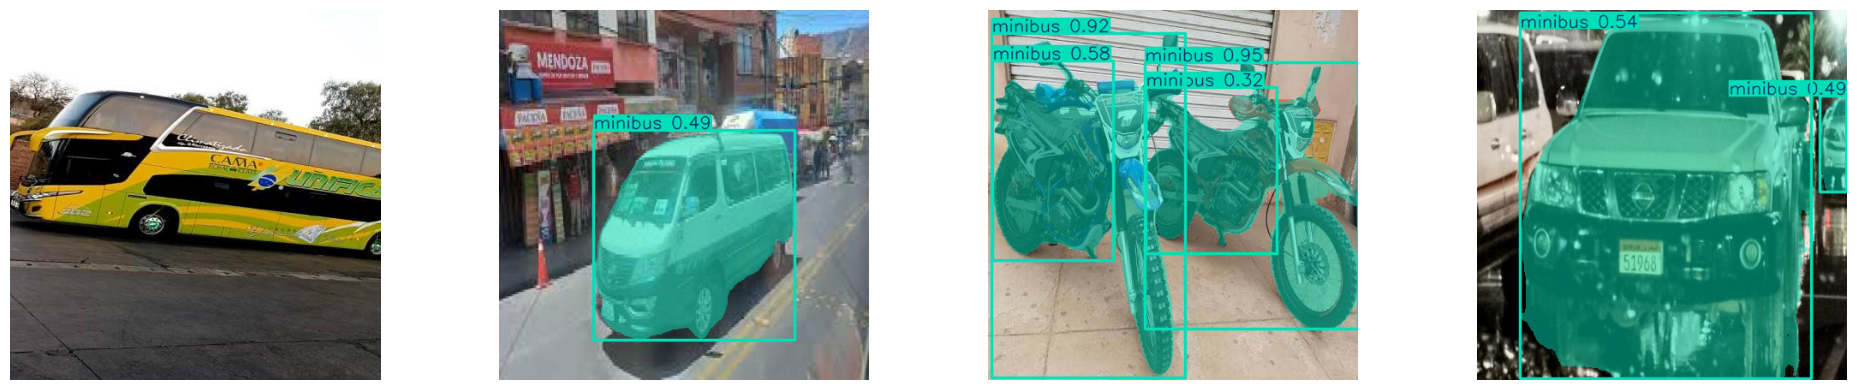

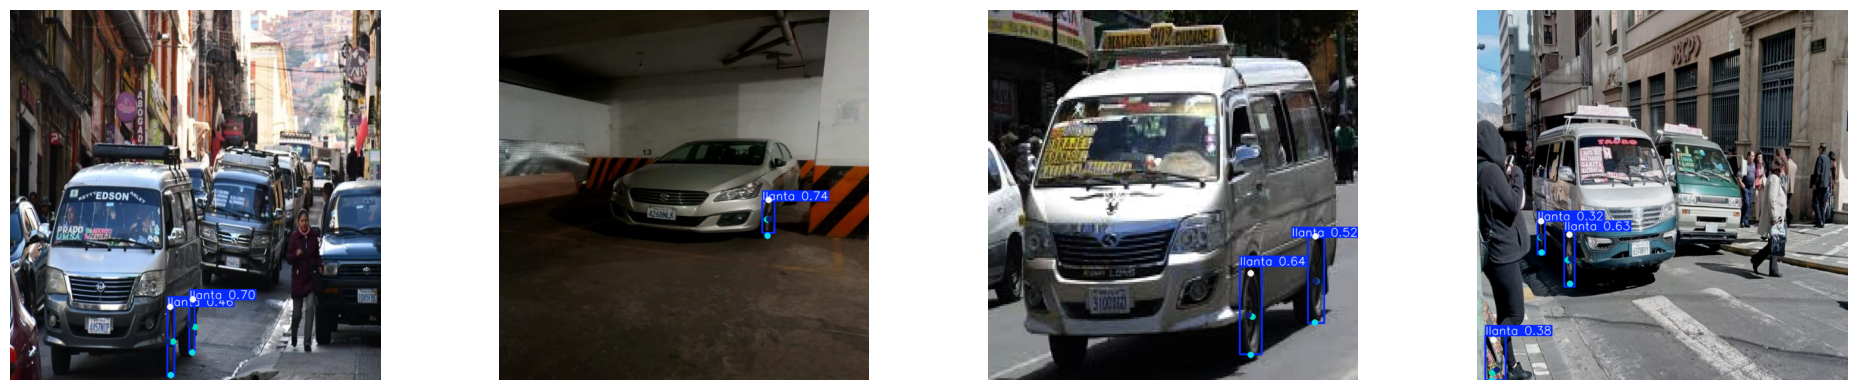

In [10]:
import matplotlib.pyplot as plt, cv2, random
def muestra(pesos, ds, n=4, **kw):
    imgs = glob.glob(ds.location + '/valid/images/*') or glob.glob(ds.location + '/val/images/*')
    elegidas = random.sample(imgs, min(n, len(imgs)))
    fig, ax = plt.subplots(1, len(elegidas), figsize=(5 * len(elegidas), 4))
    for a, p in zip(ax if len(elegidas) > 1 else [ax], elegidas):
        a.imshow(cv2.cvtColor(YOLO(pesos).predict(p, verbose=False, **kw)[0].plot(), cv2.COLOR_BGR2RGB)); a.axis('off')
    plt.tight_layout(); plt.show()
muestra(SALIDA + '/m2_vehiculos.pt', ds2)
muestra(SALIDA + '/m3_llantas.pt', ds3, imgsz=IMGSZ_M3)